In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la
import pandas as pd
from scipy.special import logit, expit

In [2]:
import KECENI

In [3]:
from true_model import mu, pij, rX

# save directory and random seed

In [4]:
save_dir = 'data'

In [5]:
np.random.seed(123456)

# parameters

In [6]:
n_sim = 80
n_pre = 4000
d_latent = 2

In [7]:
n_node = 1000
rho = 2

# latent position and network

In [8]:
Zs_pre = np.random.uniform(-2, 2, (n_pre, d_latent))

In [9]:
Zs_pre, Zs_pre.shape

(array([[-1.49212067,  1.86687135],
        [-0.95809598,  1.5889461 ],
        [-0.49300114, -0.65511302],
        ...,
        [ 0.05134932, -0.70245351],
        [ 1.62826082, -0.74815006],
        [-1.31650752,  0.51140061]]),
 (4000, 2))

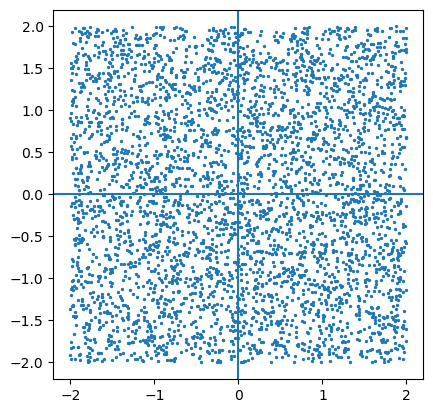

In [10]:
plt.gca().set_aspect('equal')
plt.scatter(*Zs_pre.T, s=2)
plt.axhline(y=0); plt.axvline(x=0)

In [11]:
# P = np.exp(-2-80*np.max(np.abs(Zs[:,None,:] - Zs[None,:,:])**2, axis=-1))
P = np.exp(- np.exp(10*np.max(np.abs(Zs_pre[:,None,:] - Zs_pre[None,:,:]), axis=-1)))

In [12]:
P, P.shape

(array([[3.67879441e-001, 2.64069541e-091, 0.00000000e+000, ...,
         0.00000000e+000, 0.00000000e+000, 0.00000000e+000],
        [2.64069541e-091, 3.67879441e-001, 0.00000000e+000, ...,
         0.00000000e+000, 0.00000000e+000, 0.00000000e+000],
        [0.00000000e+000, 0.00000000e+000, 3.67879441e-001, ...,
         3.70580726e-101, 0.00000000e+000, 0.00000000e+000],
        ...,
        [0.00000000e+000, 0.00000000e+000, 3.70580726e-101, ...,
         3.67879441e-001, 0.00000000e+000, 0.00000000e+000],
        [0.00000000e+000, 0.00000000e+000, 0.00000000e+000, ...,
         0.00000000e+000, 3.67879441e-001, 0.00000000e+000],
        [0.00000000e+000, 0.00000000e+000, 0.00000000e+000, ...,
         0.00000000e+000, 0.00000000e+000, 3.67879441e-001]]),
 (4000, 4000))

In [13]:
ths = np.random.random((n_pre, n_pre))

In [14]:
Adj_pre = (ths <= rho * P).astype(int)
Adj_pre[np.arange(n_pre), np.arange(n_pre)] = 0
Adj_pre[*np.tril_indices(n_pre)] = Adj_pre.T[*np.tril_indices(n_pre)]

Text(0, 0.5, 'freq')

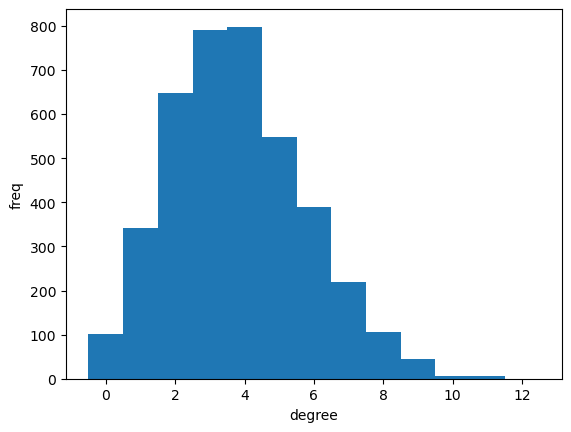

In [15]:
plt.hist(np.sum(Adj_pre,0), np.arange(np.max(np.sum(Adj_pre,0))+1)-0.5)
plt.xlabel('degree'); plt.ylabel('freq')

In [16]:
id_node = np.argsort(np.max(np.abs(Zs_pre), -1))[:n_node]

In [17]:
Adj = Adj_pre[id_node[:,None],id_node]
Zs = Zs_pre[id_node]

In [18]:
degree = np.sum(Adj, 0)

In [19]:
id_cntr = np.argmin(np.where(degree == 4, np.max(np.abs(Zs), -1), np.inf)); id_cntr

0

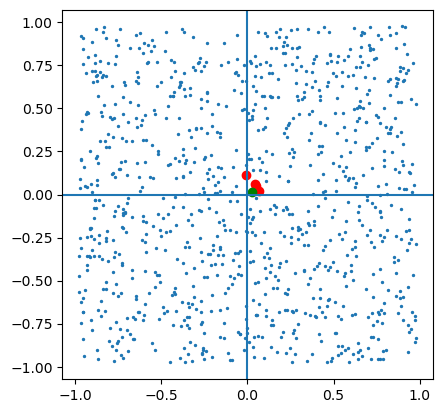

In [20]:
plt.gca().set_aspect('equal')
plt.scatter(*Zs.T, s=2)
plt.scatter(*Zs[Adj[0]==1].T, color='red')
plt.scatter(*Zs[0], color='green')
plt.axhline(y=0); plt.axvline(x=0)

In [21]:
G = KECENI.Graph(Adj, Zs)

In [22]:
row, col = np.where(Adj != 0)

Text(0, 0.5, '$Z_{i2}$')

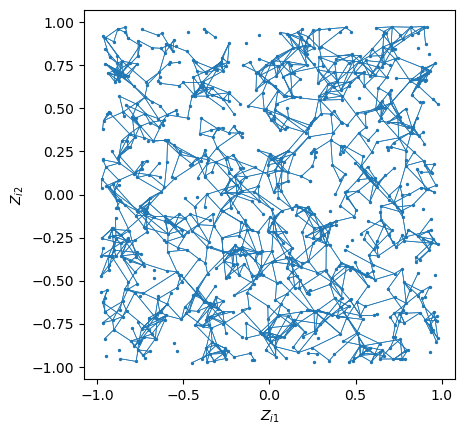

In [23]:
plt.gca().set_aspect('equal')
plt.scatter(*Zs.T, s=2)

for i, (r,c) in enumerate(zip(row, col)):
    plt.plot(*Zs[[r,c]].T, color='C0', linewidth=0.5)
    
plt.xlabel(r'$Z_{i1}$'); plt.ylabel(r'$Z_{i2}$')

In [24]:
data_latent = pd.DataFrame({'Z1': Zs[:,0], 'Z2': Zs[:,1]})
data_network = pd.DataFrame({'row': row+1, 'col': col+1})

In [25]:
data_latent.to_feather('%s/latent.feather'%save_dir)
data_network.to_feather('%s/network.feather'%save_dir)

# features

In [26]:
for i_sim in np.arange(n_sim):
    Xs = rX(1, np.arange(n_node), G)[0]
    
    ps = np.array([
        pij(1, Xs[G.N1(i)], G.sub(G.N1(i))) 
        for i in np.arange(n_node)
    ])
    
    Ts = np.random.binomial(1, ps) 
    
    ms = np.array([
        mu(Ts[G.N1(i)], Xs[G.N2(i)], G.sub(G.N2(i))) 
        for i in np.arange(n_node)
    ])
    
    Ys = np.random.normal(ms, 1)
    
    data_feature = pd.DataFrame({
        'X1': Xs[:,0], 'X2': Xs[:,1], 'X3': Xs[:,2],
        'p': ps, 'T': Ts, 'm': ms, 'Y': Ys
    })
    
    data_feature.to_feather(
        '%s/feature_%.3d.feather'%(save_dir, i_sim)
    )

# check

In [27]:
i_sim = 0

In [28]:
data_feature = pd.read_feather(
    '%s/feature_%.3d.feather'%(save_dir, i_sim)
)

(array([ 31.,  83., 103., 153., 140., 150., 157., 116.,  51.,  16.]),
 array([0.08237987, 0.16792894, 0.253478  , 0.33902707, 0.42457613,
        0.5101252 , 0.59567426, 0.68122333, 0.76677239, 0.85232146,
        0.93787052]),
 <BarContainer object of 10 artists>)

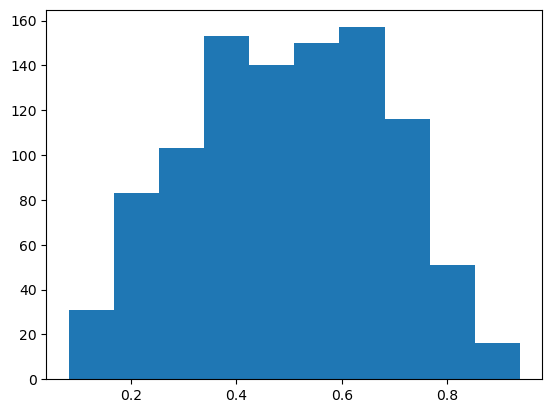

In [29]:
plt.hist(data_feature['p'])

In [30]:
np.mean(data_feature['T'])

0.519

(array([  8.,  27.,  97., 181., 223., 225., 143.,  70.,  18.,   8.]),
 array([-8.68680435, -6.85940741, -5.03201047, -3.20461354, -1.3772166 ,
         0.45018034,  2.27757728,  4.10497422,  5.93237116,  7.7597681 ,
         9.58716504]),
 <BarContainer object of 10 artists>)

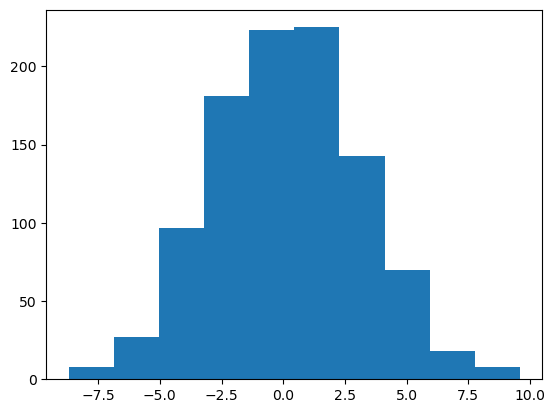

In [31]:
plt.hist(data_feature['Y'])

(array([  5.,   9.,  42.,  79., 106., 107.,  94.,  53.,  11.,  13.]),
 array([-8.68680435, -6.97793125, -5.26905815, -3.56018505, -1.85131195,
        -0.14243885,  1.56643426,  3.27530736,  4.98418046,  6.69305356,
         8.40192666]),
 <BarContainer object of 10 artists>)

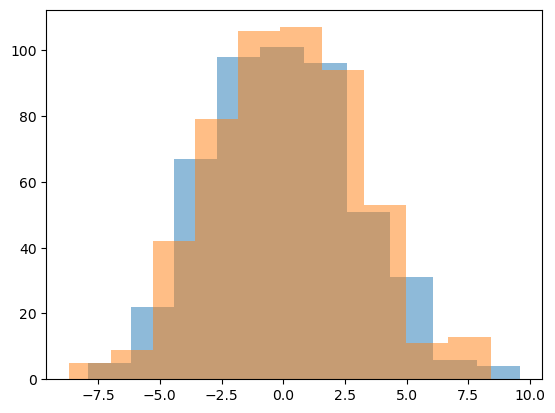

In [32]:
plt.hist(data_feature.query('T == 0')['Y'], alpha=0.5)
plt.hist(data_feature.query('T == 1')['Y'], alpha=0.5)

In [33]:
np.mean(data_feature.query('T == 0')['Y']), np.mean(data_feature.query('T == 1')['Y'])

(0.08185429881084112, 0.1681951704726106)

(array([  2.,   7.,  28.,  98., 126., 130.,  86.,  34.,   5.,   3.]),
 array([-3.07052118, -2.40557028, -1.74061937, -1.07566847, -0.41071756,
         0.25423335,  0.91918425,  1.58413516,  2.24908606,  2.91403697,
         3.57898787]),
 <BarContainer object of 10 artists>)

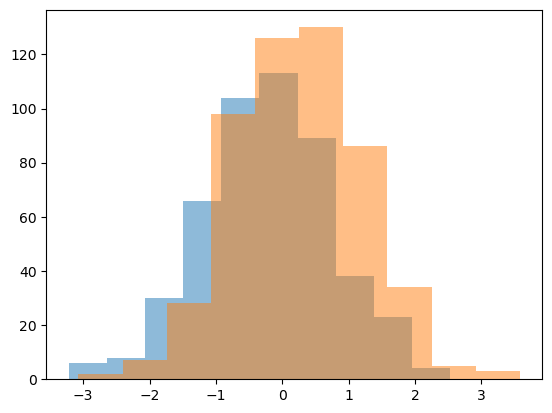

In [34]:
plt.hist(data_feature.query('T == 0')['X1'], alpha=0.5)
plt.hist(data_feature.query('T == 1')['X1'], alpha=0.5)

(array([ 12.,  25.,  55.,  80., 104., 109.,  71.,  47.,  12.,   4.]),
 array([-2.48494643, -1.93199958, -1.37905274, -0.8261059 , -0.27315906,
         0.27978779,  0.83273463,  1.38568147,  1.93862832,  2.49157516,
         3.044522  ]),
 <BarContainer object of 10 artists>)

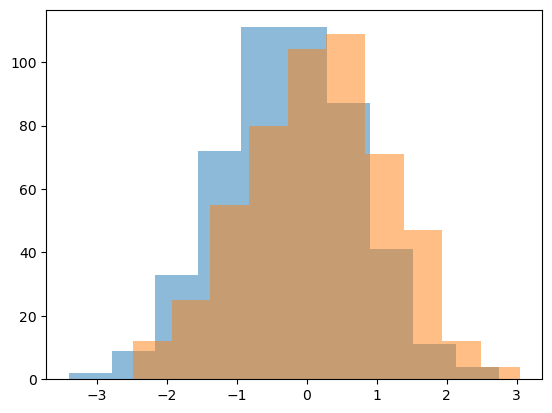

In [35]:
plt.hist(data_feature.query('T == 0')['X2'], alpha=0.5)
plt.hist(data_feature.query('T == 1')['X2'], alpha=0.5)

(array([  3.,  12.,  38.,  84., 118., 102.,  92.,  48.,  19.,   3.]),
 array([-2.68418635, -2.1162523 , -1.54831825, -0.98038421, -0.41245016,
         0.15548389,  0.72341793,  1.29135198,  1.85928603,  2.42722007,
         2.99515412]),
 <BarContainer object of 10 artists>)

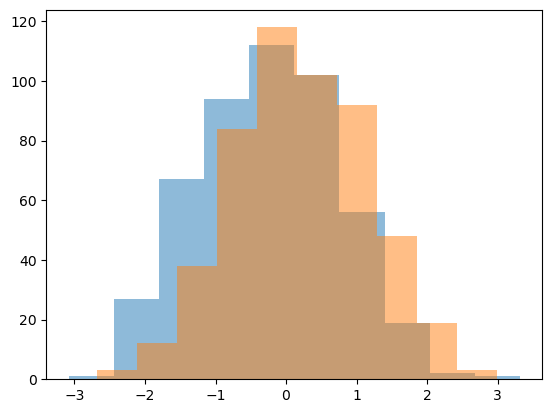

In [36]:
plt.hist(data_feature.query('T == 0')['X3'], alpha=0.5)
plt.hist(data_feature.query('T == 1')['X3'], alpha=0.5)

In [37]:
np.mean(data_feature.query('T == 0').iloc[:,0:3], 0)

X1   -0.232368
X2   -0.236628
X3   -0.243979
dtype: float64

In [38]:
np.mean(data_feature.query('T == 1').iloc[:,0:3], 0)

X1    0.240439
X2    0.166603
X3    0.219135
dtype: float64

In [39]:
np.mean(data_feature.query('T == 1').iloc[:,0:3], 0) - np.mean(data_feature.query('T == 0').iloc[:,0:3], 0)

X1    0.472806
X2    0.403232
X3    0.463114
dtype: float64